<a href="https://colab.research.google.com/github/MennaAtef8/House-Price-Prediction-Using-Artificial-Neural-Networks/blob/main/House_Price_ANN_visualize.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense
from sklearn.metrics import mean_squared_error,r2_score


In [ ]:
dataset = pd.read_csv('bj_housing.csv')
x = dataset.iloc[:,[0,2,3,4,5,6]].values
y = dataset.iloc[:,1].values

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30)

In [ ]:
x_train,x_val,y_train,y_val=train_test_split(x,y,test_size=0.2)

In [ ]:
x.shape


(9999, 6)

In [ ]:
!pip install tensorflow==2.1.0

ERROR: Could not find a version that satisfies the requirement tensorflow==2.1.0 (from versions: 2.12.0rc0, 2.12.0rc1, 2.12.0, 2.12.1, 2.13.0rc0, 2.13.0rc1, 2.13.0rc2, 2.13.0, 2.13.1, 2.14.0rc0, 2.14.0rc1, 2.14.0, 2.14.1, 2.15.0rc0, 2.15.0rc1, 2.15.0, 2.15.0.post1, 2.15.1, 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0)
ERROR: No matching distribution found for tensorflow==2.1.0


In [ ]:
print(tf.__version__)

2.18.0


In [ ]:
model = Sequential()
model.add(Dense(64, input_shape=(6,), activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(1))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,561 (10.00 KB)

 Trainable params: 2,561 (10.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss='binary_crossentropy', optimizer='adam' ,metrics=['mean_squared_error'])
hist =model.fit(x_train ,y_train ,epochs=100, validation_data=(x_val,y_val), batch_size=10)

Epoch 1/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 5523.9561 - mean_squared_error: 498190.2188 - val_loss: 5359.2290 - val_mean_squared_error: 466184.0938
Epoch 2/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 5567.6821 - mean_squared_error: 511485.0938 - val_loss: 5359.2290 - val_mean_squared_error: 466184.0938
Epoch 3/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 5574.5703 - mean_squared_error: 499966.3125 - val_loss: 5359.2290 - val_mean_squared_error: 466184.0938
Epoch 4/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5502.4619 - mean_squared_error: 494673.4062 - val_loss: 5359.2290 - val_mean_squared_error: 466184.0938
Epoch 5/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 5597.6064 - mean_squared_error: 514181.4062 - val_loss: 5359.2290 - val_mean_squared_error: 466184.0938
Epoch 6/100
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 5634.1538 - mean_squared_error: 524599.6250 - val_loss: 5359.2290 - val_mean_squared_error: 466184.0938
Epoch 7/10

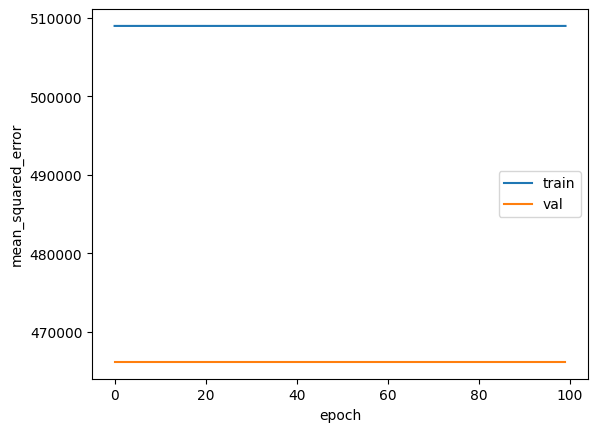

In [ ]:
plt.plot(hist.history['mean_squared_error'])
plt.plot(hist.history['val_mean_squared_error'])
plt.xlabel('epoch')
plt.ylabel('mean_squared_error')
plt.title('')
plt.legend(['train','val'])
plt.show()